# Milestone 4: DANet-S Training with ColorJitter

**Contributor:** Shanker

This notebook records the completed 75-epoch training experiment using the
training-only ColorJitter change proposed in M3. The selected epoch 62 checkpoint
has validation loss **0.08110992** and validation accuracy **97.21%**.

This is an evaluator copy of a run completed across two runtime sessions.
Original successful outputs and all three embedded figures are retained.
Execution counts identify the original session and have not been renumbered.
The training invocation is disabled by default to preserve the completed run.
Rerunning setup and artifact cells requires the original Drive files and dataset.

The test split was reserved for the separate evaluation notebook. These are
validation results, not evidence of improved test performance.

## 1. Environment and Shared Artifacts


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")
M4_DATA_DIR = PROJECT_DIR / "milestone4" / "data_preparation"
TRAINING_DIR = PROJECT_DIR / "milestone4" / "model_training"
FIGURES_DIR = TRAINING_DIR / "figures"

MANIFEST_PATH = M4_DATA_DIR / "split_manifest.csv"
CONFIG_PATH = M4_DATA_DIR / "data_config.json"

TRAINING_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("M4 manifest found:", MANIFEST_PATH.exists())
print("M4 configuration found:", CONFIG_PATH.exists())
print("Training outputs:", TRAINING_DIR)

M4 manifest found: True
M4 configuration found: True
Training outputs: /content/drive/MyDrive/malaria_danet/milestone4/model_training


In [4]:
import json

with open(CONFIG_PATH, "r") as file:
    data_config = json.load(file)

print(json.dumps(data_config, indent=2))

{
  "dataset": "NIH/NLM Malaria Cell Images",
  "dataset_url": "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip",
  "base_paper": "DANet: A Lightweight Dilated Attention Network for Malaria Parasite Detection",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "baseline_variant": "DANet-S with LogSoftMax",
  "total_images": 27558,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "split_seed": 42,
  "split_ratios": {
    "train": 0.7,
    "validation": 0.1,
    "test": 0.2
  },
  "split_counts": {
    "train": 19290,
    "validation": 2756,
    "test": 5512
  },
  "input_size": [
    224,
    224
  ],
  "pixel_scaling": "[0, 255] to [0, 1]",
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2,
    "color_jitter": {
      "brightness": 0.2,
      "contrast": 0.2,
      "saturation": 0.1,
      "hue": 0.02
    }
  },
  

## 2. Split Manifest and Experiment Verification


In [5]:
import hashlib

manifest_hash = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()

assert manifest_hash == data_config["baseline_manifest_sha256"]
assert data_config["milestone"] == 4
assert data_config["training_augmentation"]["color_jitter"] == {
    "brightness": 0.2,
    "contrast": 0.2,
    "saturation": 0.1,
    "hue": 0.02,
}

print("Split manifest matches the baseline exactly.")
print("ColorJitter settings match the M3 experiment plan.")

Split manifest matches the baseline exactly.
ColorJitter settings match the M3 experiment plan.


In [6]:
import pandas as pd

manifest = pd.read_csv(MANIFEST_PATH)

assert len(manifest) == data_config["total_images"]
assert manifest["relative_path"].is_unique
assert manifest["split"].value_counts().to_dict() == data_config["split_counts"]
assert manifest["label"].eq(
    manifest["class_name"].map(data_config["class_mapping"])
).all()

print("Manifest shape:", manifest.shape)
print("Class counts by split:")
display(pd.crosstab(manifest["split"], manifest["class_name"]))

Manifest shape: (27558, 9)
Class counts by split:


class_name,Parasitized,Uninfected
split,,
test,2756,2756
train,9645,9645
validation,1378,1378


## 3. Dataset Acquisition and Path Validation


In [7]:
DATA_ROOT = Path("/content/malaria_data")
IMAGE_ROOT = DATA_ROOT / "cell_images"
ZIP_PATH = DATA_ROOT / "cell_images.zip"

DATASET_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Image folder:", IMAGE_ROOT)
print("Dataset already extracted:", IMAGE_ROOT.is_dir())
print("Dataset archive found:", ZIP_PATH.is_file())

Image folder: /content/malaria_data/cell_images
Dataset already extracted: False
Dataset archive found: False


In [8]:
import subprocess

subprocess.run(
    ["wget", "-c", "--show-progress", "-O", str(ZIP_PATH), DATASET_URL],
    check=True,
)

print(f"Downloaded file size: {ZIP_PATH.stat().st_size / 1024**2:.1f} MB")

Downloaded file size: 337.1 MB


In [9]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_ROOT)

image_paths = manifest["relative_path"].map(lambda path: IMAGE_ROOT / path)
missing_paths = image_paths[~image_paths.map(Path.exists)]

print("Manifest images:", len(image_paths))
print("Missing images:", len(missing_paths))

assert missing_paths.empty, "Some manifest images are missing."

print("Dataset extracted and all manifest paths verified.")

Manifest images: 27558
Missing images: 0
Dataset extracted and all manifest paths verified.


## 4. Reproducibility, Transforms, and Data Loaders


In [10]:
import random

import numpy as np

SEED = data_config["split_seed"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Reproducibility seed:", SEED)
print("cuDNN deterministic:", torch.backends.cudnn.deterministic)
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

Reproducibility seed: 42
cuDNN deterministic: True
cuDNN benchmark: False


In [11]:
from torchvision import transforms

image_size = tuple(data_config["input_size"])
augmentation = data_config["training_augmentation"]

train_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomRotation(augmentation["rotation_degrees"]),
    transforms.RandomHorizontalFlip(
        p=augmentation["horizontal_flip_probability"]
    ),
    transforms.RandomVerticalFlip(
        p=augmentation["vertical_flip_probability"]
    ),
    transforms.ColorJitter(**augmentation["color_jitter"]),
    transforms.ToTensor(),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

print("Training transformations:")
print(train_transform)

print("\nEvaluation transformations:")
print(evaluation_transform)

Training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.2)
    RandomVerticalFlip(p=0.2)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.9, 1.1), hue=(-0.02, 0.02))
    ToTensor()
)

Evaluation transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


In [12]:
from PIL import Image
from torch.utils.data import Dataset

class MalariaManifestDataset(Dataset):
    def __init__(self, records, image_root, transform=None):
        self.records = records.reset_index(drop=True).copy()
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]
        image_path = self.image_root / row["relative_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        return image, label

print("Manifest dataset class ready.")

Manifest dataset class ready.


In [13]:
train_dataset = MalariaManifestDataset(
    manifest[manifest["split"] == "train"],
    IMAGE_ROOT,
    transform=train_transform,
)

validation_dataset = MalariaManifestDataset(
    manifest[manifest["split"] == "validation"],
    IMAGE_ROOT,
    transform=evaluation_transform,
)

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Reserved test images:", int((manifest["split"] == "test").sum()))

Training images: 19290
Validation images: 2756
Reserved test images: 5512


In [14]:
from torch.utils.data import DataLoader

batch_size = data_config["batch_size"]
train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=data_config["data_loader_workers"],
    pin_memory=True,
    generator=train_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=data_config["data_loader_workers"],
    pin_memory=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Batch size:", batch_size)
print("Data-loader workers:", data_config["data_loader_workers"])

Training batches: 302
Validation batches: 44
Batch size: 64
Data-loader workers: 0


## 5. Training Batch Validation


In [15]:
images, labels = next(iter(train_loader))

assert images.shape == (batch_size, 3, *image_size)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert torch.isfinite(images).all()
assert images.min().item() >= 0.0
assert images.max().item() <= 1.0
assert set(labels.tolist()).issubset(data_config["class_mapping"].values())

print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Pixel range:", images.min().item(), "to", images.max().item())
print("Class counts:", torch.bincount(labels, minlength=2))
print("Training batch checks passed.")

Image batch shape: (64, 3, 224, 224)
Label batch shape: (64,)
Image dtype: torch.float32
Pixel range: 0.0 to 1.0
Class counts: tensor([37, 27])
Training batch checks passed.


## 6. Baseline DANet-S Architecture

The architecture and binary classifier match M2. ColorJitter changes the training input pipeline only.


In [16]:
import torch.nn as nn

class DilatedAttentionBlockS(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.input_projection = nn.Conv2d(
            in_channels, in_channels, kernel_size=1,
        )

        self.dilated_conv_1 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=1, dilation=1,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.dilated_conv_2 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=2, dilation=2,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.dilated_conv_3 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=3, dilation=3,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.average_pool = nn.AvgPool2d(
            kernel_size=3, stride=1, padding=1,
        )
        self.maximum_pool = nn.MaxPool2d(
            kernel_size=3, stride=1, padding=1,
        )

        self.attention_features = nn.Sequential(
            nn.Conv2d(
                6 * in_channels, in_channels,
                kernel_size=3, padding=1,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.attention_projection = nn.Conv2d(
            in_channels, in_channels, kernel_size=1,
        )
        self.channel_attention = nn.Softmax(dim=1)

        self.output_projection = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1),
            nn.InstanceNorm2d(out_channels, affine=True),
            nn.LeakyReLU(),
        )

    def forward(self, inputs):
        projected = self.input_projection(inputs)

        features_1 = self.dilated_conv_1(projected)
        features_2 = self.dilated_conv_2(features_1)
        features_3 = self.dilated_conv_3(features_2)

        multiscale_features = torch.cat(
            [features_1, features_2, features_3], dim=1,
        )

        pooled_features = torch.cat(
            [
                self.average_pool(multiscale_features),
                self.maximum_pool(multiscale_features),
            ],
            dim=1,
        )

        attention = self.attention_features(pooled_features)
        attention = self.attention_projection(attention)
        attention = self.channel_attention(attention)

        return self.output_projection(attention * inputs)

print("Dilated attention block ready.")

Dilated attention block ready.


In [17]:
class DANetS(nn.Module):
    def __init__(self, num_classes=2, base_channels=8):
        super().__init__()

        channels = base_channels

        self.stem = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.block_1 = DilatedAttentionBlockS(channels, channels)
        self.pool_1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_2 = DilatedAttentionBlockS(channels, 2 * channels)
        self.block_3 = DilatedAttentionBlockS(2 * channels, 2 * channels)
        self.pool_2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_4 = DilatedAttentionBlockS(2 * channels, 4 * channels)
        self.block_5 = DilatedAttentionBlockS(4 * channels, 4 * channels)
        self.pool_3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_6 = DilatedAttentionBlockS(4 * channels, 8 * channels)
        self.block_7 = DilatedAttentionBlockS(8 * channels, 8 * channels)
        self.pool_4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_8 = DilatedAttentionBlockS(8 * channels, 16 * channels)
        self.block_9 = DilatedAttentionBlockS(16 * channels, 16 * channels)

        self.global_pool = nn.AvgPool2d(kernel_size=7, stride=2)
        self.flatten = nn.Flatten()

        self.classifier = nn.Sequential(
            nn.Linear(16 * channels, 8 * channels),
            nn.ReLU(),
            nn.Linear(8 * channels, num_classes),
            nn.LogSoftmax(dim=1),
        )

    def forward(self, inputs):
        features = self.stem(inputs)

        features = self.block_1(features)
        features = self.pool_1(features)

        features = self.block_2(features)
        features = self.block_3(features)
        features = self.pool_2(features)

        features = self.block_4(features)
        features = self.block_5(features)
        features = self.pool_3(features)

        features = self.block_6(features)
        features = self.block_7(features)
        features = self.pool_4(features)

        features = self.block_8(features)
        features = self.block_9(features)

        features = self.global_pool(features)
        features = self.flatten(features)

        return self.classifier(features)

print("DANet-S architecture ready.")

DANet-S architecture ready.


In [18]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

train_generator.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DANetS(
    num_classes=len(data_config["class_mapping"]),
).to(device)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

assert trainable_parameters == 2_310_842

print("Device:", device)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print("Model initialized from scratch.")

Device: cuda
Total parameters: 2,310,842
Trainable parameters: 2,310,842
Model initialized from scratch.


In [19]:
model.eval()

with torch.no_grad():
    sample_outputs = model(images[:2].to(device))
    probability_sums = sample_outputs.exp().sum(dim=1)

assert sample_outputs.shape == (2, 2)
assert torch.isfinite(sample_outputs).all()
assert torch.allclose(
    probability_sums,
    torch.ones_like(probability_sums),
    atol=1e-5,
)

print("Output shape:", tuple(sample_outputs.shape))
print("Log probabilities:")
print(sample_outputs.cpu())
print("Probability sums:", probability_sums.cpu())

model.train()

Output shape: (2, 2)
Log probabilities:
tensor([[-0.6489, -0.7394],
        [-0.6477, -0.7407]])
Probability sums: tensor([1.0000, 1.0000])


DANetS(
  (stem): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_1): DilatedAttentionBlockS(
    (input_projection): Conv2d(8, 8, kernel_size=(1, 1), stride=(1, 1))
    (dilated_conv_1): Sequential(
      (0): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): InstanceNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (dilated_conv_2): Sequential(
      (0): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2))
      (1): InstanceNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (dilated_conv_3): Sequential(
      (0): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(3, 3), dilation=(3, 3))
      (1): InstanceNorm2d(8, eps=1e-05, momentum=0.1, a

## 7. Planned Training Configuration

The following cells show the original plan: mixed precision through epoch 24,
then a fresh optimizer and full precision from epoch 25. Actual recovery occurred
earlier, after epoch 22; the final configuration and recovery notes below record
that deviation. The intermediate configuration is superseded by the final one.


In [20]:
BASELINE_TRAINING_CONFIG_PATH = (
    PROJECT_DIR
    / "danet_training"
    / "danet_training_config_final.json"
)

assert BASELINE_TRAINING_CONFIG_PATH.is_file(), (
    f"Baseline training configuration missing: {BASELINE_TRAINING_CONFIG_PATH}"
)

with open(BASELINE_TRAINING_CONFIG_PATH, "r") as file:
    baseline_training_config = json.load(file)

print(json.dumps(baseline_training_config, indent=2))

{
  "model": "DANet-S",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "num_classes": 2,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "input_size": [
    224,
    224
  ],
  "batch_size": 64,
  "total_epochs": 75,
  "optimizer": "RMSprop",
  "loss": "NLLLoss",
  "scheduler": "OneCycleLR",
  "checkpoint_criterion": "lowest validation loss",
  "seed": 42,
  "training_phases": [
    {
      "epochs": "1-24",
      "maximum_learning_rate": 0.001,
      "mixed_precision": true
    },
    {
      "epochs": "25-75",
      "maximum_learning_rate": 0.0005,
      "mixed_precision": false,
      "restart_from_epoch": 24
    }
  ],
  "selected_epoch": 67,
  "selected_validation_loss": 0.0959623521950815,
  "selected_validation_accuracy": 0.966255442670537,
  "model_file": "danet_s_best_final.pth",
  "model_sha256": "d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1",
  "test_set_evaluated": false
}


In [21]:
NUM_EPOCHS = baseline_training_config["total_epochs"]
PHASE_1_END = 24

PHASE_1_MAX_LR = baseline_training_config["training_phases"][0][
    "maximum_learning_rate"
]
PHASE_2_MAX_LR = baseline_training_config["training_phases"][1][
    "maximum_learning_rate"
]

BEST_CHECKPOINT_PATH = TRAINING_DIR / "danet_s_colorjitter_best.pth"
LAST_CHECKPOINT_PATH = TRAINING_DIR / "danet_s_colorjitter_last_state.pth"
TRAINING_HISTORY_PATH = TRAINING_DIR / "danet_colorjitter_history.csv"
TRAINING_CONFIG_PATH = TRAINING_DIR / "danet_colorjitter_config.json"

assert NUM_EPOCHS == 75
assert device.type == "cuda", "Use a GPU runtime for this training schedule."

print("Total epochs:", NUM_EPOCHS)
print("Epochs 1–24: mixed precision, maximum LR =", PHASE_1_MAX_LR)
print("Epochs 25–75: full precision, maximum LR =", PHASE_2_MAX_LR)
print("Optimizer and scheduler restart before epoch 25.")
print("Checkpoint selection: lowest validation loss")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)

Total epochs: 75
Epochs 1–24: mixed precision, maximum LR = 0.001
Epochs 25–75: full precision, maximum LR = 0.0005
Optimizer and scheduler restart before epoch 25.
Checkpoint selection: lowest validation loss
Best checkpoint: /content/drive/MyDrive/malaria_danet/milestone4/model_training/danet_s_colorjitter_best.pth


In [22]:
criterion = nn.NLLLoss()

optimizer = torch.optim.RMSprop(
    model.parameters(),
    lr=PHASE_1_MAX_LR,
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=PHASE_1_MAX_LR,
    epochs=NUM_EPOCHS,
    steps_per_epoch=len(train_loader),
)

amp_enabled = True

gradient_scaler = torch.amp.GradScaler(
    device.type,
    enabled=amp_enabled,
)

print("Loss:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Scheduler:", scheduler.__class__.__name__)
print("Mixed precision enabled:", amp_enabled)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Loss: NLLLoss
Optimizer: RMSprop
Scheduler: OneCycleLR
Mixed precision enabled: True
Initial learning rate: 3.9999999999999996e-05


In [23]:
from copy import deepcopy

training_config = {
    "experiment": data_config["experiment"],
    "model": "DANet-S",
    "num_classes": len(data_config["class_mapping"]),
    "class_mapping": data_config["class_mapping"],
    "input_size": data_config["input_size"],
    "batch_size": batch_size,
    "data_loader_workers": data_config["data_loader_workers"],
    "seed": SEED,
    "total_epochs": NUM_EPOCHS,
    "optimizer": "RMSprop",
    "loss": "NLLLoss",
    "scheduler": "OneCycleLR",
    "training_phases": deepcopy(baseline_training_config["training_phases"]),
    "phase_1_scheduler_epochs": NUM_EPOCHS,
    "phase_2_scheduler_epochs": NUM_EPOCHS - PHASE_1_END,
    "phase_2_optimizer_reinitialized": True,
    "training_augmentation": data_config["training_augmentation"],
    "split_manifest_sha256": manifest_hash,
    "initialization": "from scratch",
    "checkpoint_criterion": "lowest validation loss",
    "test_set_evaluated": False,
}

with open(TRAINING_CONFIG_PATH, "w") as file:
    json.dump(training_config, file, indent=2)

print(json.dumps(training_config, indent=2))
print("\nTraining configuration saved:", TRAINING_CONFIG_PATH)

{
  "experiment": "DANet-S with mild ColorJitter",
  "model": "DANet-S",
  "num_classes": 2,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "input_size": [
    224,
    224
  ],
  "batch_size": 64,
  "data_loader_workers": 0,
  "seed": 42,
  "total_epochs": 75,
  "optimizer": "RMSprop",
  "loss": "NLLLoss",
  "scheduler": "OneCycleLR",
  "training_phases": [
    {
      "epochs": "1-24",
      "maximum_learning_rate": 0.001,
      "mixed_precision": true
    },
    {
      "epochs": "25-75",
      "maximum_learning_rate": 0.0005,
      "mixed_precision": false,
      "restart_from_epoch": 24
    }
  ],
  "phase_1_scheduler_epochs": 75,
  "phase_2_scheduler_epochs": 51,
  "phase_2_optimizer_reinitialized": true,
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2,
    "color_jitter": {
      "brightness": 0.2,
      "contrast": 0.2,
      "saturation": 0.1,
      "hue": 0.02
    }
  

## 8. Training, Validation, and Checkpoint Functions

The training function handles loss-scaler skips without advancing the scheduler for a skipped optimizer update. Non-finite losses stop the run.


In [24]:
def train_one_epoch():
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    skipped_updates = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled,
        ):
            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss. Stop and inspect.")

        previous_scale = gradient_scaler.get_scale()

        gradient_scaler.scale(loss).backward()
        gradient_scaler.step(optimizer)
        gradient_scaler.update()

        if gradient_scaler.get_scale() >= previous_scale:
            scheduler.step()
        else:
            skipped_updates += 1

        batch_count = batch_labels.size(0)
        total_loss += loss.item() * batch_count
        total_correct += (
            outputs.argmax(dim=1) == batch_labels
        ).sum().item()
        total_samples += batch_count

    print("Skipped mixed-precision updates:", skipped_updates)

    return total_loss / total_samples, total_correct / total_samples

print("Training function updated.")

Training function updated.


In [25]:
def validate_one_epoch():
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for batch_images, batch_labels in validation_loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=amp_enabled,
            ):
                outputs = model(batch_images)
                loss = criterion(outputs, batch_labels)

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Non-finite validation loss. Stop and inspect."
                )

            batch_count = batch_labels.size(0)
            total_loss += loss.item() * batch_count
            total_correct += (
                outputs.argmax(dim=1) == batch_labels
            ).sum().item()
            total_samples += batch_count

    return total_loss / total_samples, total_correct / total_samples

print("Validation function ready.")

Validation function ready.


In [26]:
def save_checkpoint(checkpoint, path):
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(path)


def save_training_state(epoch, best_record, training_history):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "gradient_scaler_state_dict": gradient_scaler.state_dict(),
        "amp_enabled": amp_enabled,
        "best_record": dict(best_record),
        "training_history": list(training_history),
        "training_config": training_config,
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_random_state": torch.get_rng_state(),
        "cuda_random_states": torch.cuda.get_rng_state_all(),
        "loader_generator_state": train_generator.get_state(),
    }

    save_checkpoint(checkpoint, LAST_CHECKPOINT_PATH)

print("Checkpoint-saving functions ready.")
print("Resume checkpoint:", LAST_CHECKPOINT_PATH)

Checkpoint-saving functions ready.
Resume checkpoint: /content/drive/MyDrive/malaria_danet/milestone4/model_training/danet_s_colorjitter_last_state.pth


## 9. Training Recovery Record

The first epoch's loss scaler adjusted its scale by skipping five updates.
During epoch 23, mixed-precision training produced a non-finite loss. That
incomplete epoch was discarded and the finite epoch 22 checkpoint was restored.
Epochs 23-75 then used full precision, a fresh RMSprop optimizer, and a new
53-epoch OneCycleLR schedule with maximum learning rate 0.0005.

The obsolete epoch-zero restore, failed initialization, duplicate training loops,
and old recovery commands have been removed. The original successful metric
logs below are retained as historical transcripts; they do not execute training.
The full retained metrics for epochs 1-75 are in `artifacts/danet_colorjitter_history.csv`.

M2 switched precision after epoch 24, whereas this run switched after epoch 22.
That difference limits attribution of result changes solely to ColorJitter.


### Initial epoch

Saved output from the original training session:

```text
Starting epoch 1/75...
Skipped mixed-precision updates: 5
Epoch 1: train loss=0.5476, accuracy=0.6872 | val loss=0.1868, accuracy=0.9445 | time=211.0s

Best epoch: 1
Best validation loss: 0.1867651546479396
Current loss scale: 2048.0
Resume checkpoint saved: True
Training history saved: True
```


### Mixed-precision continuation

Saved output from the original training session:

```text
Starting epoch 2/75...
Skipped mixed-precision updates: 1
Epoch 2: train loss=0.1939, accuracy=0.9373 | val loss=0.1469, accuracy=0.9554 | time=206.0s
Starting epoch 3/75...
Skipped mixed-precision updates: 0
Epoch 3: train loss=0.1618, accuracy=0.9508 | val loss=0.1654, accuracy=0.9445 | time=207.9s
Starting epoch 4/75...
Skipped mixed-precision updates: 0
Epoch 4: train loss=0.1622, accuracy=0.9511 | val loss=0.1352, accuracy=0.9594 | time=208.7s
Starting epoch 5/75...
Skipped mixed-precision updates: 0
Epoch 5: train loss=0.1532, accuracy=0.9546 | val loss=0.1777, accuracy=0.9478 | time=210.9s
Starting epoch 6/75...
Skipped mixed-precision updates: 0
Epoch 6: train loss=0.1647, accuracy=0.9496 | val loss=0.1742, accuracy=0.9568 | time=208.9s
Starting epoch 7/75...
Skipped mixed-precision updates: 0
Epoch 7: train loss=0.1599, accuracy=0.9536 | val loss=0.1448, accuracy=0.9590 | time=209.6s
Starting epoch 8/75...
Skipped mixed-precision updates: 0
Epoch 8: train loss=0.1562, accuracy=0.9542 | val loss=0.1676, accuracy=0.9459 | time=209.9s
Starting epoch 9/75...
Skipped mixed-precision updates: 0
Epoch 9: train loss=0.1555, accuracy=0.9527 | val loss=0.1463, accuracy=0.9568 | time=209.0s
Starting epoch 10/75...
Skipped mixed-precision updates: 0
Epoch 10: train loss=0.1598, accuracy=0.9544 | val loss=0.2576, accuracy=0.9187 | time=208.4s
Starting epoch 11/75...
Skipped mixed-precision updates: 0
Epoch 11: train loss=0.1491, accuracy=0.9566 | val loss=0.1384, accuracy=0.9572 | time=208.1s
Starting epoch 12/75...
Skipped mixed-precision updates: 0
Epoch 12: train loss=0.1489, accuracy=0.9553 | val loss=0.1333, accuracy=0.9619 | time=208.8s
Starting epoch 13/75...
Skipped mixed-precision updates: 0
Epoch 13: train loss=0.1459, accuracy=0.9553 | val loss=0.1473, accuracy=0.9507 | time=207.5s
Starting epoch 14/75...
Skipped mixed-precision updates: 0
Epoch 14: train loss=0.1412, accuracy=0.9561 | val loss=0.1332, accuracy=0.9604 | time=206.0s
Starting epoch 15/75...
Skipped mixed-precision updates: 0
Epoch 15: train loss=0.1480, accuracy=0.9538 | val loss=0.1342, accuracy=0.9579 | time=206.8s
Starting epoch 16/75...
Skipped mixed-precision updates: 0
Epoch 16: train loss=0.1392, accuracy=0.9574 | val loss=0.1339, accuracy=0.9597 | time=207.2s
Starting epoch 17/75...
Skipped mixed-precision updates: 0
Epoch 17: train loss=0.1370, accuracy=0.9571 | val loss=0.1277, accuracy=0.9615 | time=207.2s
Starting epoch 18/75...
Skipped mixed-precision updates: 0
Epoch 18: train loss=0.1328, accuracy=0.9578 | val loss=0.1215, accuracy=0.9608 | time=207.6s
Starting epoch 19/75...
Skipped mixed-precision updates: 0
Epoch 19: train loss=0.1251, accuracy=0.9602 | val loss=0.1630, accuracy=0.9488 | time=206.9s
Starting epoch 20/75...
Skipped mixed-precision updates: 0
Epoch 20: train loss=0.1252, accuracy=0.9598 | val loss=0.1122, accuracy=0.9637 | time=210.0s
Starting epoch 21/75...
Skipped mixed-precision updates: 0
Epoch 21: train loss=0.1168, accuracy=0.9618 | val loss=0.1084, accuracy=0.9652 | time=211.6s
Starting epoch 22/75...
Skipped mixed-precision updates: 0
Epoch 22: train loss=0.1144, accuracy=0.9625 | val loss=0.0998, accuracy=0.9681 | time=211.2s
Starting epoch 23/75...
```


### Restored finite checkpoint

Saved output from the original training session:

```text
Restored completed epoch: 22
Next epoch: 23
History records: 22
Model parameters finite: True
Best epoch: 22
Best validation loss: 0.09978700378174381
```


### Full-precision recovery setup

Saved output from the original training session:

```text
Next epoch: 23
Remaining epochs: 53
Mixed precision enabled: False
Maximum learning rate: 0.0005
Recovery configuration and resume checkpoint saved.
```


### First recovered epoch

Saved output from the original training session:

```text
Starting epoch 23/75...
Skipped mixed-precision updates: 0
Epoch 23: train loss=0.0965, accuracy=0.9671 | val loss=0.0949, accuracy=0.9710 | time=234.2s

Completed epochs: 23
Best epoch: 23
Best validation loss: 0.09494520559182447
Best validation accuracy: 0.9709724238026125
Resume checkpoint saved: True
```


## 10. Runtime Continuation and Completed Training

The following saved outputs show the continuation from completed epoch 68.
On a later rerun, the latest checkpoint may already contain epoch 75.
The 53-epoch second-phase scheduler is restored, rather than restarted for the
remaining epochs. The final training invocation is disabled by default;
its saved output below is the original log for epochs 69-75.


In [28]:
checkpoint = torch.load(
    LAST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

assert device.type == "cuda", "Select a GPU runtime before resuming."

saved_epoch = int(checkpoint["epoch"])
saved_history = checkpoint["training_history"]

assert len(saved_history) == saved_epoch
assert checkpoint["amp_enabled"] is False

print("Last completed epoch:", saved_epoch)
print("Next epoch:", saved_epoch + 1)
print("Remaining epochs:", 75 - saved_epoch)
print("History records:", len(saved_history))
print("Best result:", checkpoint["best_record"])
print("Saved scheduler step:", checkpoint["scheduler_state_dict"]["last_epoch"])
print("Saved training phases:")
print(json.dumps(
    checkpoint["training_config"]["training_phases"],
    indent=2,
))

Last completed epoch: 68
Next epoch: 69
Remaining epochs: 7
History records: 68
Best result: {'epoch': 62, 'validation_loss': 0.08110992054879755, 'validation_accuracy': 0.9720609579100146}
Saved scheduler step: 13892
Saved training phases:
[
  {
    "epochs": "1-22",
    "maximum_learning_rate": 0.001,
    "mixed_precision": true
  },
  {
    "epochs": "23-75",
    "maximum_learning_rate": 0.0005,
    "mixed_precision": false,
    "restart_from_epoch": 22
  }
]


In [29]:
training_config = checkpoint["training_config"]
NUM_EPOCHS = training_config["total_epochs"]

model.load_state_dict(checkpoint["model_state_dict"])

amp_enabled = False
gradient_scaler = torch.amp.GradScaler(
    device.type,
    enabled=False,
)

phase_two = training_config["training_phases"][1]

optimizer = torch.optim.RMSprop(
    model.parameters(),
    lr=phase_two["maximum_learning_rate"],
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=phase_two["maximum_learning_rate"],
    epochs=training_config["phase_2_scheduler_epochs"],
    steps_per_epoch=len(train_loader),
)

optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
gradient_scaler.load_state_dict(checkpoint["gradient_scaler_state_dict"])

start_epoch = int(checkpoint["epoch"])
best_record = dict(checkpoint["best_record"])
training_history = list(checkpoint["training_history"])

random.setstate(checkpoint["python_random_state"])
np.random.set_state(checkpoint["numpy_random_state"])
torch.set_rng_state(checkpoint["torch_random_state"])
torch.cuda.set_rng_state_all(checkpoint["cuda_random_states"])
train_generator.set_state(checkpoint["loader_generator_state"])

optimizer.zero_grad(set_to_none=True)

assert all(
    torch.isfinite(parameter).all().item()
    for parameter in model.parameters()
)
assert scheduler.last_epoch == checkpoint["scheduler_state_dict"]["last_epoch"]

with open(TRAINING_CONFIG_PATH, "w") as file:
    json.dump(training_config, file, indent=2)

print("Restored epoch:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Scheduler step:", scheduler.last_epoch)
print("Current learning rate:", optimizer.param_groups[0]["lr"])
print("Mixed precision enabled:", amp_enabled)
print("Model parameters are finite.")
print("Recovered training configuration saved.")

Restored epoch: 68
Next epoch: 69
Scheduler step: 13892
Current learning rate: 4.261125602361416e-05
Mixed precision enabled: False
Model parameters are finite.
Recovered training configuration saved.


In [30]:
import time

def resume_training(end_epoch):
    global start_epoch, best_record

    assert not amp_enabled
    assert start_epoch < end_epoch <= NUM_EPOCHS

    for epoch in range(start_epoch + 1, end_epoch + 1):
        print(f"Starting epoch {epoch}/{NUM_EPOCHS}...", flush=True)
        started_at = time.perf_counter()

        train_loss, train_accuracy = train_one_epoch()
        validation_loss, validation_accuracy = validate_one_epoch()

        if not all(
            torch.isfinite(parameter).all().item()
            for parameter in model.parameters()
        ):
            raise RuntimeError("Non-finite model parameters. Stop and inspect.")

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "mixed_precision": amp_enabled,
            "epoch_seconds": time.perf_counter() - started_at,
        }

        if validation_loss < best_record["validation_loss"]:
            best_record = {
                "epoch": epoch,
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
            }

            save_checkpoint({
                **best_record,
                "model_state_dict": model.state_dict(),
                "training_config": training_config,
            }, BEST_CHECKPOINT_PATH)

        training_history.append(record)
        save_training_state(epoch, best_record, training_history)

        temporary_history = TRAINING_HISTORY_PATH.with_suffix(".csv.tmp")
        pd.DataFrame(training_history).to_csv(temporary_history, index=False)
        temporary_history.replace(TRAINING_HISTORY_PATH)

        start_epoch = epoch

        print(
            f"Epoch {epoch}: "
            f"train loss={train_loss:.4f}, accuracy={train_accuracy:.4f} | "
            f"val loss={validation_loss:.4f}, accuracy={validation_accuracy:.4f} | "
            f"time={record['epoch_seconds']:.1f}s",
            flush=True,
        )

print("Resume loop ready. Next epoch:", start_epoch + 1)

Resume loop ready. Next epoch: 69


In [31]:
RUN_TRAINING = False

if RUN_TRAINING and start_epoch < NUM_EPOCHS:
    resume_training(end_epoch=NUM_EPOCHS)

print("\nTraining completed.")
print("Completed epochs:", start_epoch)
print("Best epoch:", best_record["epoch"])
print("Best validation loss:", best_record["validation_loss"])
print("Best validation accuracy:", best_record["validation_accuracy"])
print("Best checkpoint:", BEST_CHECKPOINT_PATH)

Starting epoch 69/75...
Skipped mixed-precision updates: 0
Epoch 69: train loss=0.0634, accuracy=0.9779 | val loss=0.0861, accuracy=0.9710 | time=245.5s
Starting epoch 70/75...
Skipped mixed-precision updates: 0
Epoch 70: train loss=0.0609, accuracy=0.9783 | val loss=0.0852, accuracy=0.9717 | time=248.9s
Starting epoch 71/75...
Skipped mixed-precision updates: 0
Epoch 71: train loss=0.0617, accuracy=0.9777 | val loss=0.0839, accuracy=0.9724 | time=246.5s
Starting epoch 72/75...
Skipped mixed-precision updates: 0
Epoch 72: train loss=0.0604, accuracy=0.9784 | val loss=0.0843, accuracy=0.9717 | time=243.3s
Starting epoch 73/75...
Skipped mixed-precision updates: 0
Epoch 73: train loss=0.0590, accuracy=0.9791 | val loss=0.0845, accuracy=0.9713 | time=245.7s
Starting epoch 74/75...
Skipped mixed-precision updates: 0
Epoch 74: train loss=0.0597, accuracy=0.9790 | val loss=0.0847, accuracy=0.9710 | time=250.3s
Starting epoch 75/75...
Skipped mixed-precision updates: 0
Epoch 75: train loss=0.

## 11. Verification of the Complete 75-Epoch History


In [32]:
history_df = pd.read_csv(TRAINING_HISTORY_PATH)

metric_columns = [
    "train_loss",
    "train_accuracy",
    "validation_loss",
    "validation_accuracy",
    "learning_rate",
    "epoch_seconds",
]

assert history_df["epoch"].tolist() == list(range(1, NUM_EPOCHS + 1))
assert np.isfinite(history_df[metric_columns].to_numpy()).all()
assert history_df["mixed_precision"].tolist() == (
    [True] * 22 + [False] * 53
)

selected_row = history_df.loc[
    history_df["validation_loss"].idxmin()
]

assert int(selected_row["epoch"]) == best_record["epoch"]
assert np.isclose(
    selected_row["validation_loss"],
    best_record["validation_loss"],
)

print("History verified: 75 consecutive epochs, with finite metrics.")
print("Selected checkpoint:")
display(selected_row.to_frame("value"))

print("Final five epochs:")
display(history_df.tail())

History verified: 75 consecutive epochs, with finite metrics.
Selected checkpoint:


,value
epoch,62
train_loss,0.071313
train_accuracy,0.974028
validation_loss,0.08111
validation_accuracy,0.972061
learning_rate,0.000137
mixed_precision,False
epoch_seconds,239.196442


Final five epochs:


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,learning_rate,mixed_precision,epoch_seconds
70,71,0.061661,0.977657,0.083857,0.972424,1.418315e-05,False,246.485804
71,72,0.060411,0.978434,0.084282,0.971698,8.007930e-06,False,243.332077
72,73,0.058953,0.979108,0.084492,0.971335,3.566890e-06,False,245.715731
73,74,0.059708,0.978953,0.084672,0.970972,8.918596e-07,False,250.348074
74,75,0.057206,0.979212,0.084753,0.970610,2.009828e-09,False,245.365872


## 12. Training and Validation Curves


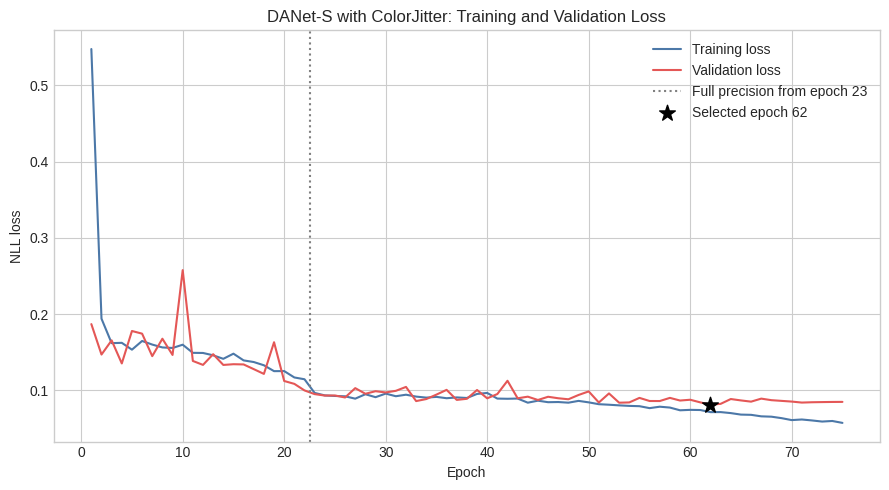

In [33]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training loss",
    color="#4C78A8",
)
ax.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation loss",
    color="#E45756",
)

ax.axvline(
    22.5,
    color="gray",
    linestyle=":",
    label="Full precision from epoch 23",
)
ax.scatter(
    best_record["epoch"],
    best_record["validation_loss"],
    color="black",
    marker="*",
    s=140,
    label=f"Selected epoch {best_record['epoch']}",
    zorder=5,
)

ax.set_title("DANet-S with ColorJitter: Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("NLL loss")
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_validation_loss.png", dpi=200)
plt.show()

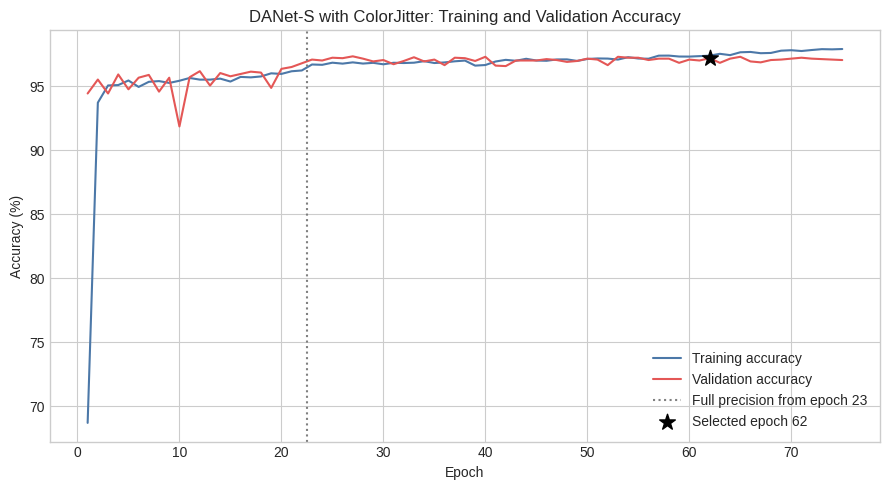

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    label="Training accuracy",
    color="#4C78A8",
)
ax.plot(
    history_df["epoch"],
    history_df["validation_accuracy"] * 100,
    label="Validation accuracy",
    color="#E45756",
)

ax.axvline(
    22.5,
    color="gray",
    linestyle=":",
    label="Full precision from epoch 23",
)
ax.scatter(
    best_record["epoch"],
    best_record["validation_accuracy"] * 100,
    color="black",
    marker="*",
    s=140,
    label=f"Selected epoch {best_record['epoch']}",
    zorder=5,
)

ax.set_title("DANet-S with ColorJitter: Training and Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_validation_accuracy.png", dpi=200)
plt.show()

## 13. Recorded Learning Rate Schedule

Values are the learning rates recorded at the end of each completed epoch.


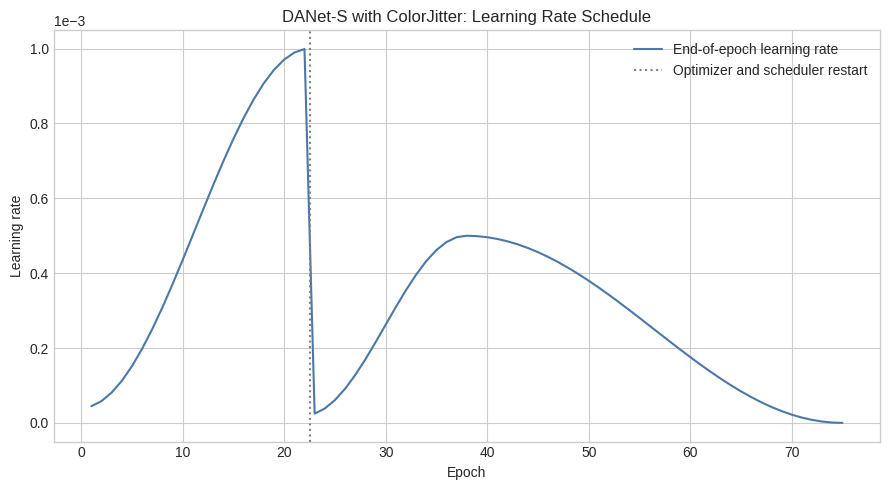

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    history_df["epoch"],
    history_df["learning_rate"],
    color="#4C78A8",
    label="End-of-epoch learning rate",
)

ax.axvline(
    22.5,
    color="gray",
    linestyle=":",
    label="Optimizer and scheduler restart",
)

ax.set_title("DANet-S with ColorJitter: Learning Rate Schedule")
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "learning_rate_schedule.png", dpi=200)
plt.show()

## 14. Selected Checkpoint Verification


In [36]:
best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

assert best_checkpoint["epoch"] == best_record["epoch"]
assert np.isclose(
    best_checkpoint["validation_loss"],
    best_record["validation_loss"],
)
assert np.isclose(
    best_checkpoint["validation_accuracy"],
    best_record["validation_accuracy"],
)
assert all(
    torch.isfinite(value).all().item()
    for value in best_checkpoint["model_state_dict"].values()
)

model_sha256 = hashlib.sha256(
    BEST_CHECKPOINT_PATH.read_bytes()
).hexdigest()

model_size_mb = BEST_CHECKPOINT_PATH.stat().st_size / 1024**2

print("Selected epoch:", best_checkpoint["epoch"])
print("Validation loss:", best_checkpoint["validation_loss"])
print("Validation accuracy:", best_checkpoint["validation_accuracy"])
print(f"Checkpoint size: {model_size_mb:.2f} MB")
print("SHA-256:", model_sha256)
print("Selected checkpoint verified.")

Selected epoch: 62
Validation loss: 0.08110992054879755
Validation accuracy: 0.9720609579100146
Checkpoint size: 8.90 MB
SHA-256: ee7bc1fd413439343fda5a3b8dddad5f0a6bdbe98981488da2c1eb56775f30b3
Selected checkpoint verified.


## 15. Final Experiment Configuration


In [37]:
final_training_config = deepcopy(training_config)

final_training_config.update({
    "completed_epochs": int(history_df["epoch"].max()),
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
    "selected_epoch": int(best_checkpoint["epoch"]),
    "selected_validation_loss": float(
        best_checkpoint["validation_loss"]
    ),
    "selected_validation_accuracy": float(
        best_checkpoint["validation_accuracy"]
    ),
    "model_file": BEST_CHECKPOINT_PATH.name,
    "model_size_bytes": BEST_CHECKPOINT_PATH.stat().st_size,
    "model_sha256": model_sha256,
    "retained_training_minutes": float(
        history_df["epoch_seconds"].sum() / 60
    ),
    "runtime_resume_after_epoch": 68,
    "comparison_limitation": (
        "The baseline switched to full precision after epoch 24; "
        "this experiment switched after epoch 22 due to non-finite loss. "
        "Training schedules therefore differ, so performance differences "
        "cannot be attributed solely to ColorJitter."
    ),
    "test_set_evaluated": False,
})

FINAL_CONFIG_PATH = TRAINING_DIR / "danet_colorjitter_config_final.json"

with open(FINAL_CONFIG_PATH, "w") as file:
    json.dump(final_training_config, file, indent=2)

print(json.dumps(final_training_config, indent=2))
print("\nFinal configuration saved:", FINAL_CONFIG_PATH)

{
  "experiment": "DANet-S with mild ColorJitter",
  "model": "DANet-S",
  "num_classes": 2,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "input_size": [
    224,
    224
  ],
  "batch_size": 64,
  "data_loader_workers": 0,
  "seed": 42,
  "total_epochs": 75,
  "optimizer": "RMSprop",
  "loss": "NLLLoss",
  "scheduler": "OneCycleLR",
  "training_phases": [
    {
      "epochs": "1-22",
      "maximum_learning_rate": 0.001,
      "mixed_precision": true
    },
    {
      "epochs": "23-75",
      "maximum_learning_rate": 0.0005,
      "mixed_precision": false,
      "restart_from_epoch": 22
    }
  ],
  "phase_1_scheduler_epochs": 75,
  "phase_2_scheduler_epochs": 53,
  "phase_2_optimizer_reinitialized": true,
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2,
    "color_jitter": {
      "brightness": 0.2,
      "contrast": 0.2,
      "saturation": 0.1,
      "hue": 0.02
    }
  

## 16. Resumed Runtime Environment

This environment record covers epochs 69-75 and artifact preparation.


In [38]:
import platform

import PIL
import torchvision

training_environment = {
    "scope": "Resumed runtime: epochs 69-75 and artifact preparation",
    "python": platform.python_version(),
    "pytorch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": torch.cuda.get_device_name(0),
}

ENVIRONMENT_PATH = TRAINING_DIR / "training_environment.json"

with open(ENVIRONMENT_PATH, "w") as file:
    json.dump(training_environment, file, indent=2)

print(json.dumps(training_environment, indent=2))
print("\nEnvironment saved:", ENVIRONMENT_PATH)

{
  "scope": "Resumed runtime: epochs 69-75 and artifact preparation",
  "python": "3.13.16",
  "pytorch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "cuda": "13.0",
  "cudnn": 92700,
  "gpu": "Tesla T4"
}

Environment saved: /content/drive/MyDrive/malaria_danet/milestone4/model_training/training_environment.json


## 17. Training Summary and Evaluation Handoff


In [39]:
summary = f"""# Milestone 4: DANet-S ColorJitter Training

## Experiment
DANet-S trained from scratch with the mild ColorJitter settings recorded in M3.
The baseline split manifest, label mapping, and evaluation preprocessing were preserved.

## Training
- Completed epochs: 75
- Training images: {len(train_dataset):,}
- Validation images: {len(validation_dataset):,}
- Trainable parameters: {final_training_config["trainable_parameters"]:,}
- Batch size: {batch_size}
- Random seed: {SEED}
- Optimizer: RMSprop
- Loss: NLLLoss
- Scheduler: OneCycleLR
- Retained epoch time: {final_training_config["retained_training_minutes"]:.1f} minutes
- Timing excludes the failed attempt and runtime setup.

## Recovery and continuation
Epochs 1-22 used mixed precision with maximum learning rate 0.001.
Epoch 23 encountered non-finite training loss and was discarded.
The saved epoch 22 state was restored, and epochs 23-75 used full precision
with a fresh RMSprop optimizer and 53-epoch OneCycleLR schedule,
with maximum learning rate 0.0005.

After a GPU usage interruption, training resumed from the completed epoch 68
checkpoint with model, optimizer, scheduler, scaler, and random states restored.
The retained history contains exactly epochs 1-75.

## Selected checkpoint
- Selection rule: lowest validation loss
- Selected epoch: {best_checkpoint["epoch"]}
- Validation loss: {best_checkpoint["validation_loss"]:.8f}
- Validation accuracy: {best_checkpoint["validation_accuracy"]:.8f}
- Model file: {BEST_CHECKPOINT_PATH.name}
- Model size: {model_size_mb:.2f} MB
- SHA-256: {model_sha256}

## Final epoch
- Training loss: {history_df.iloc[-1]["train_loss"]:.6f}
- Training accuracy: {history_df.iloc[-1]["train_accuracy"]:.6f}
- Validation loss: {history_df.iloc[-1]["validation_loss"]:.6f}
- Validation accuracy: {history_df.iloc[-1]["validation_accuracy"]:.6f}

## Limitations and evaluation boundary
{final_training_config["comparison_limitation"]}
The image-level split retains patient overlap across partitions.
The environment record describes the resumed runtime only.
No test evaluation was performed in this notebook.
Test metrics and the baseline comparison belong to the evaluation notebook.
Keep model checkpoints in Drive; do not commit them to the repository.
"""

SUMMARY_PATH = TRAINING_DIR / "danet_colorjitter_training_summary.md"
SUMMARY_PATH.write_text(summary, encoding="utf-8")

print(summary)
print("Summary saved:", SUMMARY_PATH)

# Milestone 4: DANet-S ColorJitter Training

## Experiment
DANet-S trained from scratch with the mild ColorJitter settings recorded in M3.
The baseline split manifest, label mapping, and evaluation preprocessing were preserved.

## Training
- Completed epochs: 75
- Training images: 19,290
- Validation images: 2,756
- Trainable parameters: 2,310,842
- Batch size: 64
- Random seed: 42
- Optimizer: RMSprop
- Loss: NLLLoss
- Scheduler: OneCycleLR
- Retained epoch time: 287.5 minutes
- Timing excludes the failed attempt and runtime setup.

## Recovery and continuation
Epochs 1-22 used mixed precision with maximum learning rate 0.001.
Epoch 23 encountered non-finite training loss and was discarded.
The saved epoch 22 state was restored, and epochs 23-75 used full precision
with a fresh RMSprop optimizer and 53-epoch OneCycleLR schedule,
with maximum learning rate 0.0005.

After a GPU usage interruption, training resumed from the completed epoch 68
checkpoint with model, optimizer, scheduler,

## 18. Artifact Checksums

These saved outputs describe the original Drive exports. Repository exports reside under `artifacts/`, with PNG files in `artifacts/figures/`.


In [40]:
artifact_names = [
    "danet_colorjitter_config_final.json",
    "danet_colorjitter_history.csv",
    "training_environment.json",
    "danet_colorjitter_training_summary.md",
    "figures/training_validation_loss.png",
    "figures/training_validation_accuracy.png",
    "figures/learning_rate_schedule.png",
]

artifacts = []

for name in artifact_names:
    path = TRAINING_DIR / name
    assert path.is_file(), f"Missing artifact: {path}"

    artifacts.append({
        "filename": name,
        "size_bytes": path.stat().st_size,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    })

ARTIFACT_MANIFEST_PATH = TRAINING_DIR / "training_artifact_manifest.json"

with open(ARTIFACT_MANIFEST_PATH, "w") as file:
    json.dump(artifacts, file, indent=2)

display(pd.DataFrame(artifacts))
print("All seven training artifacts verified and recorded.")
print("Artifact manifest saved:", ARTIFACT_MANIFEST_PATH)

,filename,size_bytes,sha256
0,danet_colorjitter_config_final.json,2316,24264b752917558ec10d025d090e0d3e74a74ce5963fc4...
1,danet_colorjitter_history.csv,9632,bd90d81c5b84ea49242c8373aa170e3d844fe703232fc8...
2,training_environment.json,276,3a2d7fbf83555c6b0d3aa2e42831b95a228b7ba69653a7...
3,danet_colorjitter_training_summary.md,2101,23918efdc22c6612c0e72a2b0252f8c3fbb016bac2be64...
4,figures/training_validation_loss.png,116150,8b817f8b6639f0d1f4f5cfb4199318435155a5200da204...
5,figures/training_validation_accuracy.png,114499,249fd28fc790cf5cff18f482e174442f9741acf69fa06c...
6,figures/learning_rate_schedule.png,107182,3c1e4cc2d0c9f05bfa7c4f39546ec73011e00868e2f1c4...


All seven training artifacts verified and recorded.
Artifact manifest saved: /content/drive/MyDrive/malaria_danet/milestone4/model_training/training_artifact_manifest.json


## 19. Result and Remaining Work

Training completed 75 epochs. The checkpoint selected by lowest validation loss
is epoch 62, with validation accuracy 97.21%. No held-out test metrics were
computed here. The next notebook must evaluate that checkpoint on the fixed
test split, compare with M2 and M3 predictions, and report the schedule difference
and patient overlap. Model checkpoints remain external to Git.
